# Predicting Customer Churn in Subscription-Based Streaming Services
### Final Project Presentation: a data-driven approach to identifying at-risk subscribers

**Student:** Yura  |  **Institution:** Texas A&M International University (TAMIU)  |  **Dataset:** IBM Telco Customer Churn (public sample data, used as a proxy for a streaming subscription service)

This notebook presents the complete analytics project, from business problem to recommendations. It runs top to bottom (about one minute) in Google Colab or Jupyter, and the outputs stored in it were produced by running the code.

| Section | Content |
|---|---|
| 1 | Business problem |
| 2 | Project objectives |
| 3 | Dataset overview |
| 4 | Data preparation (live demonstration) |
| 5 | Exploratory analysis and visualizations |
| 6 | Analytical methodology |
| 7 | Code demonstration: training and evaluating the models |
| 8 | Key findings |
| 9 | Business value of the model |
| 10 | Conclusions and recommendations |
| 11 | Repository guide and use of AI |

In [1]:
# ---- Setup: locate the project folder (clones the repository first if running in a fresh Colab) ----
import os, sys, pathlib, subprocess

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "churn_pipeline").exists():          # e.g. a new Google Colab runtime
    REPO_URL = "https://github.com/YOUR-USERNAME/churn-prediction-project.git"   # <- set to your repository
    subprocess.run(["git", "clone", REPO_URL, "churn-prediction-project"], check=True)
    ROOT = pathlib.Path("churn-prediction-project").resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy import stats

from churn_pipeline import cleaning, config, data, evaluation, modeling, pipeline

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GRAY = config.BLUE, config.ORANGE, config.GRAY

print(f"Project folder: {ROOT.name}")
print(f"Python libraries: pandas {pd.__version__}, scikit-learn {sklearn.__version__}, numpy {np.__version__}")

Project folder: churn-prediction-project
Python libraries: pandas 3.0.6, scikit-learn 1.9.1, numpy 2.5.4


---
## 1. Business Problem

Subscription streaming services compete in a market where customers can cancel at any time. Every cancellation removes recurring revenue, and the company must spend money to acquire a replacement. Research on service businesses has long found that customer defections have a large effect on profit (Reichheld & Sasser, 1990).

Most providers react to churn only when a customer calls to cancel, and by then the decision has usually been made. **The core problem: the company cannot identify subscribers who are at high risk of churning *before* they cancel**, so retention teams cannot prioritize outreach, personalize offers, or act at the right moment.

**Business questions**
1. Which subscribers are most likely to churn, so outreach can be prioritized?
2. Which customer attributes are most associated with churn, so we understand *why* customers leave?
3. What should the retention team do, and how many customers should it contact?

**Stakeholders:** marketing and customer success (run retention campaigns), product and pricing managers (set contracts and plans), and executives accountable for subscriber growth.

---
## 2. Project Objectives

| # | Objective | How it is measured | Notebook section |
|---|---|---|---|
| 1 | Identify the attributes and behaviors most associated with churn | Churn rates, Cramér's V, odds ratios, Random Forest importances | 5, 8 |
| 2 | Build and evaluate a classifier that estimates each subscriber's churn probability | Held-out test set: precision, recall, F1, ROC-AUC, confusion matrix | 6, 7 |
| 3 | Turn findings into actionable recommendations | Targeting-efficiency (gains) and net-benefit analysis | 9, 10 |

Only 26.5% of customers churn, so accuracy alone is misleading: predicting "no churn" for everyone would be 73.5% accurate and find no churners. Success is judged mainly by **recall, precision, and ROC-AUC**.

---
## 3. Dataset Overview

The **IBM Telco Customer Churn** dataset is a public sample dataset published by IBM (downloaded October 5, 2026 from `github.com/IBM/telco-customer-churn-on-icp4d`). It was built for telecom churn analysis, but its structure (monthly billing, contract terms, add-on services including StreamingTV and StreamingMovies, and a stay-or-cancel outcome) matches subscription streaming data. It contains no real personal information. It is a snapshot with no signup or cancellation dates and no viewing data; this limit is discussed in Section 10.

In [2]:
raw = pd.read_csv("data/raw/telco_customer_churn_raw.csv")
print(f"{raw.shape[0]:,} customers x {raw.shape[1]} columns (one row per customer)")
raw.head()

7,043 customers x 21 columns (one row per customer)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Column inventory: type, number of distinct values, and an example value
pd.DataFrame({"dtype": raw.dtypes.astype(str), "distinct_values": raw.nunique(), "example": raw.iloc[0]})

,dtype,distinct_values,example
customerID,str,7043,7590-VHVEG
gender,str,2,Female
SeniorCitizen,int64,2,0
Partner,str,2,Yes
Dependents,str,2,No
tenure,int64,73,1
PhoneService,str,2,No
MultipleLines,str,3,No phone service
InternetService,str,3,DSL
OnlineSecurity,str,3,No


In [4]:
churn_counts = raw["Churn"].value_counts()
print(f"Retained: {churn_counts['No']:,} ({churn_counts['No']/len(raw):.1%})")
print(f"Churned:  {churn_counts['Yes']:,} ({churn_counts['Yes']/len(raw):.1%})   <- the minority class we want to find")

Retained: 5,174 (73.5%)
Churned:  1,869 (26.5%)   <- the minority class we want to find


---
## 4. Data Preparation (live demonstration)

The functions in `churn_pipeline/cleaning.py` run the quality checks and cleaning steps. The last cell of this section proves that they reproduce the cleaned file used for modeling.

In [5]:
# Integrity and quality checks on the raw table
quality = cleaning.quality_report(raw)
pd.Series(quality, name="result").to_frame()

,result
rows,7043
columns,21
duplicate_rows,0
duplicate_customer_ids,0
blank_total_charges,11
blank_all_tenure_zero,True
blank_all_retained,True


In [6]:
# The one real data problem: TotalCharges is stored as text because 11 values are blank
blank_rows = raw[raw["TotalCharges"].astype(str).str.strip() == ""]
blank_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head(5)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No


In [7]:
df = cleaning.clean_raw(raw)
print("Missing values after cleaning:", int(df.isna().sum().sum()))
print("IQR outliers (tenure, MonthlyCharges, TotalCharges):", cleaning.iqr_outlier_counts(df))

# Verify against the cleaned file produced in the data preparation milestone
saved = pd.read_csv("data/processed/telco_clean.csv")
pd.testing.assert_frame_equal(df, saved, check_dtype=False)
print("Check passed: clean_raw() reproduces data/processed/telco_clean.csv exactly.")

Missing values after cleaning: 0
IQR outliers (tenure, MonthlyCharges, TotalCharges): {'tenure': 0, 'MonthlyCharges': 0, 'TotalCharges': 0}
Check passed: clean_raw() reproduces data/processed/telco_clean.csv exactly.


**Cleaning decisions**

| Step | Finding | Action |
|---|---|---|
| Duplicates | 0 duplicate rows or customer IDs | None removed |
| Blank `TotalCharges` | 11 values, all customers with tenure = 0 who are retained (new, not yet billed) | Set to **$0**. Mean imputation would imply about $2,300 billed; deleting rows would remove valid new subscribers |
| Category consistency | "No internet service" / "No phone service" repeat other columns | Merged into "No" |
| Types | `SeniorCitizen` coded 0/1 while other flags use Yes/No | Recoded to Yes/No |
| Outliers | None by the 1.5 × IQR rule | Nothing removed |

**Design change made during modeling.** The earlier model-ready file standardized columns using *all* rows (information from the test set leaks into scaling), and it contained redundant features (`avg_monthly_spend` correlates 0.996 with `MonthlyCharges`; `num_addon_services` is the exact sum of six flags; `TotalCharges` ≈ tenure × `MonthlyCharges`). The final pipeline therefore starts from the cleaned table and does all scaling and encoding **inside the pipeline, fit on training data only**. Dropping the redundant features changed cross-validated AUC by only about 0.001. `gender` and `PhoneService` were also dropped because they show no relationship with churn (Section 5).

---
## 5. Exploratory Analysis and Visualizations

Exploration came before modeling, to understand the data and to decide which techniques fit it.

In [8]:
df["churned"] = (df["Churn"] == "Yes").astype(int)
overall = df["churned"].mean()
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80


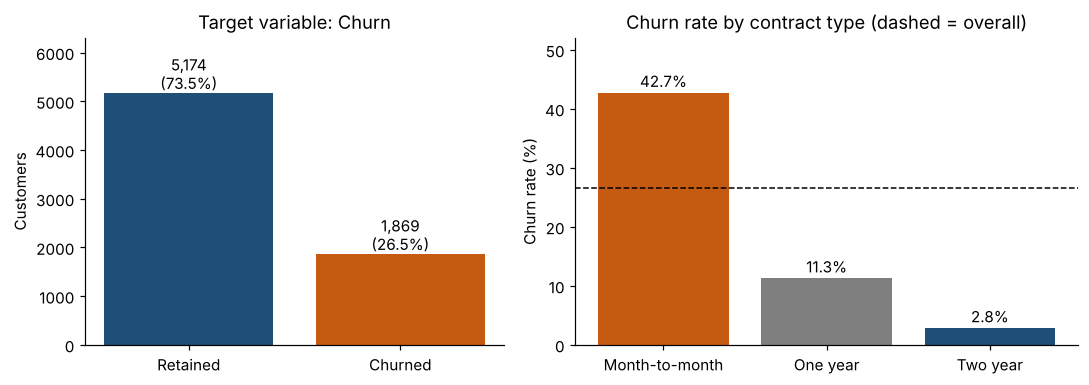

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1, 1.2]})

counts = df["Churn"].value_counts()[["No", "Yes"]]
bars = ax[0].bar(["Retained", "Churned"], counts.values, color=[BLUE, ORANGE])
for bar, value in zip(bars, counts.values):
    ax[0].text(bar.get_x() + bar.get_width() / 2, value + 80, f"{value:,}\n({value/len(df):.1%})", ha="center")
ax[0].set(ylim=(0, 6300), ylabel="Customers", title="Target variable: Churn")

by_contract = (df.groupby("Contract")["churned"].mean() * 100).reindex(["Month-to-month", "One year", "Two year"])
bars = ax[1].bar(by_contract.index, by_contract.values, color=[ORANGE, GRAY, BLUE])
ax[1].axhline(overall * 100, ls="--", color="k", lw=1)
for bar in bars:
    ax[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"{bar.get_height():.1f}%", ha="center")
ax[1].set(ylabel="Churn rate (%)", ylim=(0, 52), title="Churn rate by contract type (dashed = overall)")
plt.tight_layout()
plt.show()

**Takeaway.** Month-to-month customers churn 15 times as often as two-year customers (42.7% vs 2.8%).

Median tenure:  retained 38.0 | churned 10.0 months
Mean monthly charge: retained $61.27 | churned $74.44


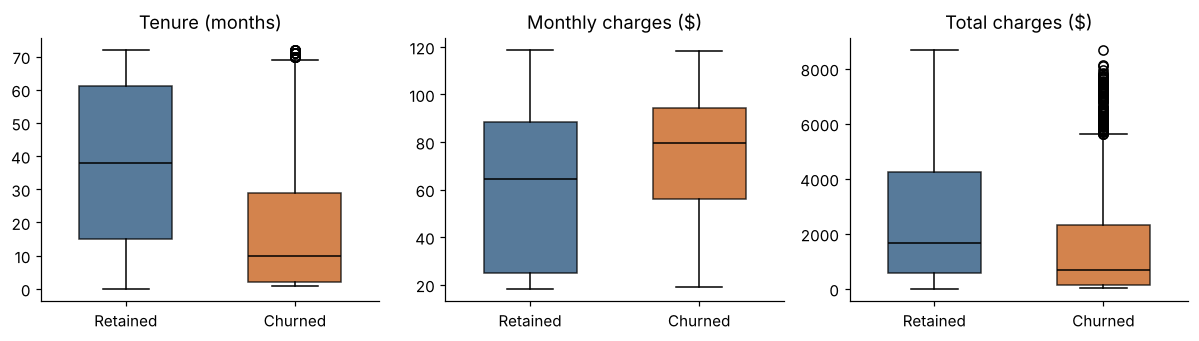

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a, col, title in zip(ax, ["tenure", "MonthlyCharges", "TotalCharges"],
                         ["Tenure (months)", "Monthly charges ($)", "Total charges ($)"]):
    boxes = a.boxplot([df.loc[df.churned == 0, col], df.loc[df.churned == 1, col]],
                      tick_labels=["Retained", "Churned"], patch_artist=True, widths=0.55,
                      medianprops=dict(color="k"))
    for box, color in zip(boxes["boxes"], [BLUE, ORANGE]):
        box.set_facecolor(color); box.set_alpha(0.75)
    a.set_title(title)
plt.tight_layout()
plt.show()

print("Median tenure:  retained", df.loc[df.churned == 0, "tenure"].median(),
      "| churned", df.loc[df.churned == 1, "tenure"].median(), "months")
print("Mean monthly charge: retained $%.2f | churned $%.2f" % (
      df.loc[df.churned == 0, "MonthlyCharges"].mean(), df.loc[df.churned == 1, "MonthlyCharges"].mean()))

In [11]:
# Which categorical attributes are associated with churn? (chi-square test + Cramér's V effect size)
categorical = [c for c in df.columns if c not in ["customerID", "Churn", "churned", "tenure", "MonthlyCharges", "TotalCharges"]]
rows = []
for col in categorical:
    table = pd.crosstab(df[col], df["churned"])
    chi2, p_value, _, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (len(df) * (min(table.shape) - 1)))
    rates = df.groupby(col)["churned"].mean() * 100
    rows.append({"attribute": col, "cramers_v": round(cramers_v, 3), "p_value": f"{p_value:.1e}",
                 "highest_risk_level": f"{rates.idxmax()} ({rates.max():.1f}%)",
                 "lowest_risk_level": f"{rates.idxmin()} ({rates.min():.1f}%)"})
association = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
association

,attribute,cramers_v,p_value,highest_risk_level,lowest_risk_level
0,Contract,0.410,5.9e-258,Month-to-month (42.7%),Two year (2.8%)
1,InternetService,0.322,9.6e-160,Fiber optic (41.9%),No (7.4%)
2,PaymentMethod,0.303,3.7e-140,Electronic check (45.3%),Credit card (automatic) (15.2%)
3,PaperlessBilling,0.191,4.1e-58,Yes (33.6%),No (16.3%)
4,OnlineSecurity,0.171,1.2e-46,No (31.3%),Yes (14.6%)
5,TechSupport,0.164,2.9e-43,No (31.2%),Yes (15.2%)
6,Dependents,0.164,4.9e-43,No (31.3%),Yes (15.5%)
7,SeniorCitizen,0.150,1.5e-36,Yes (41.7%),No (23.6%)
8,Partner,0.150,2.1e-36,No (33.0%),Yes (19.7%)
9,OnlineBackup,0.082,6.2e-12,No (29.2%),Yes (21.5%)


**Takeaway.** Contract (V = 0.41), internet service (0.32), and payment method (0.30) are the strongest signals. `gender` (V = 0.008, p = 0.49) and `PhoneService` (V = 0.011, p = 0.34) show **no relationship** with churn, so they were excluded from the models.

1,037 of 1,869 churners (55%) left within their first 12 months.


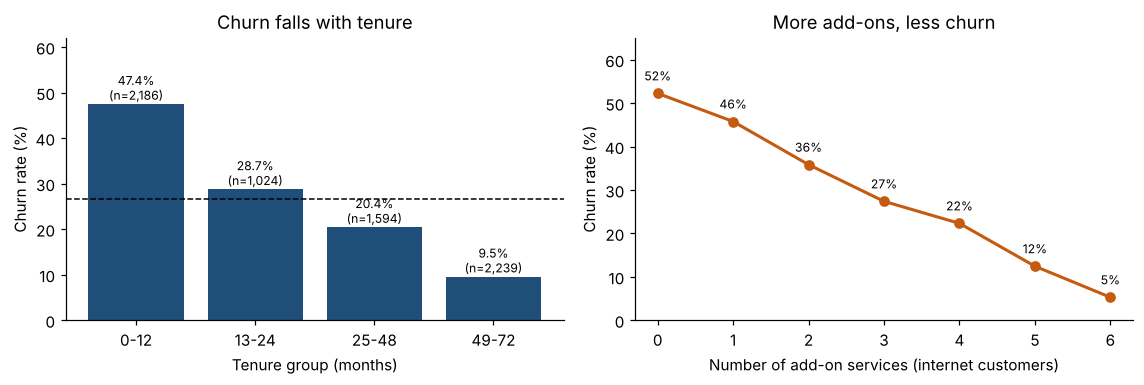

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))

df["tenure_group"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
by_tenure = df.groupby("tenure_group", observed=True)["churned"].agg(["mean", "size"])
bars = ax[0].bar(by_tenure.index.astype(str), by_tenure["mean"] * 100, color=BLUE)
for bar, n in zip(bars, by_tenure["size"]):
    ax[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"{bar.get_height():.1f}%\n(n={n:,})", ha="center", fontsize=8)
ax[0].axhline(overall * 100, ls="--", color="k", lw=1)
ax[0].set(ylim=(0, 62), xlabel="Tenure group (months)", ylabel="Churn rate (%)", title="Churn falls with tenure")

addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_addons"] = df[addons].eq("Yes").sum(axis=1)
internet = df[df["InternetService"] != "No"]
by_addons = internet.groupby("num_addons")["churned"].mean() * 100
ax[1].plot(by_addons.index, by_addons.values, marker="o", color=ORANGE, lw=2)
for x, y in by_addons.items():
    ax[1].text(x, y + 3, f"{y:.0f}%", ha="center", fontsize=8)
ax[1].set(ylim=(0, 65), xlabel="Number of add-on services (internet customers)", ylabel="Churn rate (%)",
          title="More add-ons, less churn")
plt.tight_layout()
plt.show()

first_year = ((df.tenure <= 12) & (df.churned == 1)).sum()
print(f"{first_year:,} of {df.churned.sum():,} churners ({first_year/df.churned.sum():.0%}) left within their first 12 months.")

Month-to-month fiber customers: 2,128 (30% of base), 1,162 of all 1,869 churners (62%).


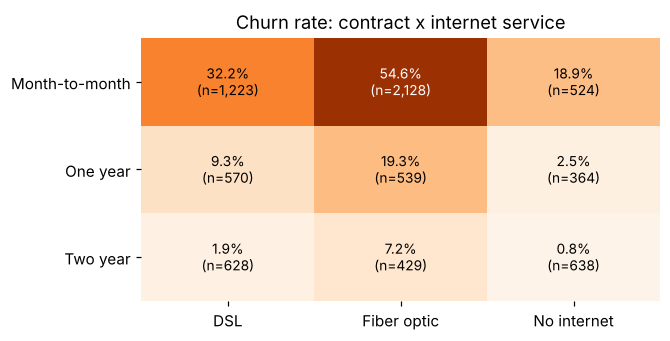

In [13]:
# Interaction: contract type x internet service
order = ["Month-to-month", "One year", "Two year"]
rates = df.pivot_table(index="Contract", columns="InternetService", values="churned", aggfunc="mean").reindex(order)[["DSL", "Fiber optic", "No"]] * 100
sizes = df.pivot_table(index="Contract", columns="InternetService", values="churned", aggfunc="size").reindex(order)[["DSL", "Fiber optic", "No"]]

fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.imshow(rates.values, cmap="Oranges", vmin=0, vmax=60, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(["DSL", "Fiber optic", "No internet"])
ax.set_yticks(range(3)); ax.set_yticklabels(order)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{rates.values[i, j]:.1f}%\n(n={sizes.values[i, j]:,})", ha="center", va="center", fontsize=9,
                color="white" if rates.values[i, j] > 40 else "black")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Churn rate: contract x internet service")
plt.tight_layout()
plt.show()

mtm_fiber = df[(df.Contract == "Month-to-month") & (df.InternetService == "Fiber optic")]
print(f"Month-to-month fiber customers: {len(mtm_fiber):,} ({len(mtm_fiber)/len(df):.0%} of base), "
      f"{mtm_fiber.churned.sum():,} of all {df.churned.sum():,} churners ({mtm_fiber.churned.sum()/df.churned.sum():.0%}).")

**What exploration told us about the methods**

| Finding | Consequence for the analysis |
|---|---|
| 26.5% churn rate | Use class weights; evaluate with recall, precision, ROC-AUC (not accuracy) |
| Skewed, U-shaped tenure; contract x internet interaction | Compare tree-based models with a linear baseline |
| Redundant billing features | Remove `TotalCharges` and the engineered duplicates |
| No effect of `gender`, `PhoneService` | Exclude them |

---
## 6. Analytical Methodology

**Problem type:** supervised binary classification (churn = 1, stay = 0).

**Workflow:** stratified 80/20 train/test split, then a *preprocessing + model* pipeline for each algorithm, tuned with 5-fold cross-validation on the training set, a decision threshold chosen from training data, and one final evaluation on the held-out test set.

| Model | Role |
|---|---|
| Logistic Regression | Interpretable baseline: odds ratios and probabilities |
| Decision Tree | Captures non-linear effects and interactions; readable rules |
| Random Forest | Ensemble of 300 trees for predictive performance and feature importance |

**Safeguards**
- **No data leakage:** scaling and encoding are fit on training folds only (they are steps inside each `Pipeline`).
- **Class imbalance:** `class_weight="balanced"` instead of resampling.
- **Tuning by cross-validated ROC-AUC** on training data; the test set is used once, for reporting.
- **Two operating points** per model: the default 0.50 cut-off and a recall-favoring cut-off that maximizes the F2 score on out-of-fold *training* predictions.
- **Automated checks** stop the run if the split overlaps, is not stratified, or a scaler was fit on non-training data.

In [14]:
# The preprocessing step, straight from the project code
import inspect
print(inspect.getsource(modeling.make_preprocessor))
print("Features scaled:", config.NUMERIC_FEATURES)
print("Columns dropped:", config.COLUMNS_TO_DROP)
print("Hyperparameter grids:")
for name, grid in config.PARAM_GRIDS.items():
    print(f"  {name}: {grid}")

def make_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    """Standardize the numeric columns and one-hot encode all the others.

    Binary columns become a single 0/1 column; unseen categories are ignored at prediction time.
    """
    categorical = [col for col in X.columns if col not in config.NUMERIC_FEATURES]
    return ColumnTransformer([
        ("num", StandardScaler(), config.NUMERIC_FEATURES),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical),
    ])

Features scaled: ['tenure', 'MonthlyCharges']
Columns dropped: ['customerID', 'gender', 'PhoneService', 'TotalCharges']
Hyperparameter grids:
  Logistic Regression: {'model__C': [0.01, 0.1, 1, 10]}
  Decision Tree: {'model__max_depth': [3, 4, 5, 6], 'model__min_samples_leaf': [20, 50, 100]}
  Random Forest: {'model__max_depth': [6, 8, 12], 'model__min_samples_leaf': [5, 20]}


In [15]:
# The threshold search and how each model is wrapped in a leakage-safe pipeline
print(inspect.getsource(modeling.find_best_threshold))
print(inspect.getsource(modeling.build_searches))

def find_best_threshold(estimator: Pipeline, X_train: pd.DataFrame, y_train: pd.Series,
                        cv: StratifiedKFold, beta: float = config.F_BETA) -> float:
    """Pick the cut-off that maximizes F-beta on out-of-fold TRAINING predictions.

    Using out-of-fold predictions means the threshold is chosen without touching the test set.
    """
    out_of_fold = cross_val_predict(
        estimator, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    scores = fbeta_for_thresholds(y_train, out_of_fold, config.THRESHOLD_GRID, beta)
    return float(config.THRESHOLD_GRID[int(np.argmax(scores))])

def build_searches(X: pd.DataFrame, cv: StratifiedKFold) -> dict[str, GridSearchCV]:
    """Create one (unfitted) grid search per model, keyed by model name."""
    estimators = {
        "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000),
        "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=config.SEED),
        "

---
## 7. Code Demonstration: Training and Evaluating the Models

`pipeline.run()` loads the cleaned data, splits it, tunes all three models, runs the sanity checks, evaluates on the test set, and saves tables and figures. This takes roughly 30 seconds.

In [16]:
import logging, time
logging.basicConfig(level=logging.INFO, format="%(message)s", stream=sys.stdout, force=True)

start = time.time()
results, odds, importances = pipeline.run("data/processed/telco_clean.csv", "outputs/latest_run")
print(f"\nFinished in {time.time() - start:.0f} seconds. Files saved to outputs/latest_run/")

All sanity checks passed.

Test-set results (train n=5634, test n=1409, churn rate 26.5%)

              model operating_point  threshold  accuracy  precision  recall    f1  roc_auc  cv_auc  train_auc
Logistic Regression            0.50       0.50     0.742      0.509   0.778 0.615    0.839   0.845      0.848
Logistic Regression      tuned (F2)       0.34     0.674      0.444   0.912 0.597    0.839   0.845      0.848
      Decision Tree            0.50       0.50     0.751      0.520   0.794 0.629    0.839   0.833      0.857
      Decision Tree      tuned (F2)       0.26     0.607      0.399   0.947 0.561    0.839   0.833      0.857
      Random Forest            0.50       0.50     0.753      0.523   0.799 0.632    0.843   0.846      0.872
      Random Forest      tuned (F2)       0.35     0.671      0.443   0.917 0.597    0.843   0.846      0.872

Best model by cross-validated ROC-AUC: Random Forest
Top 5 RF importances:
                    feature  importance
    Contract_Month-to-m

In [17]:
# Test-set results (n = 1,409 customers, 374 churners)
results.drop(columns="best_params").round(3)

,model,operating_point,threshold,accuracy,precision,recall,f1,roc_auc,cv_auc,train_auc
0,Logistic Regression,0.50,0.50,0.742,0.509,0.778,0.615,0.839,0.845,0.848
1,Logistic Regression,tuned (F2),0.34,0.674,0.444,0.912,0.597,0.839,0.845,0.848
2,Decision Tree,0.50,0.50,0.751,0.520,0.794,0.629,0.839,0.833,0.857
3,Decision Tree,tuned (F2),0.26,0.607,0.399,0.947,0.561,0.839,0.833,0.857
4,Random Forest,0.50,0.50,0.753,0.523,0.799,0.632,0.843,0.846,0.872
5,Random Forest,tuned (F2),0.35,0.671,0.443,0.917,0.597,0.843,0.846,0.872


**Reading the table.** The `0.50` rows use the conventional cut-off; the `tuned (F2)` rows use the recall-favoring cut-off chosen on training data. All three models rank customers about equally well (test ROC-AUC about 0.84), and differences are smaller than the fold-to-fold variation in cross-validation (about ±0.01), so no model is clearly best. Random Forest has the highest cross-validated AUC and is the selected model; Logistic Regression is nearly as good and easier to explain.

**Reproducibility note.** The numbers in the final report come from scikit-learn 1.8.0. Logistic Regression and Decision Tree results are identical in every version tested, while Random Forest can shift slightly between library versions. The next cell compares this run with the stored reference results.

In [18]:
reference = pd.read_csv("tests/reference_model_results.csv")
keys = ["model", "operating_point"]
comparison = results[keys + ["recall", "roc_auc"]].merge(
    reference[keys + ["recall", "roc_auc"]], on=keys, suffixes=("_this_run", "_report_reference"))
comparison["max_abs_difference"] = (
    (comparison["recall_this_run"] - comparison["recall_report_reference"]).abs()
    .combine((comparison["roc_auc_this_run"] - comparison["roc_auc_report_reference"]).abs(), max))
print(f"This run: scikit-learn {sklearn.__version__} | Report reference: scikit-learn 1.8.0")
comparison.round(3)

This run: scikit-learn 1.9.1 | Report reference: scikit-learn 1.8.0


,model,operating_point,recall_this_run,roc_auc_this_run,recall_report_reference,roc_auc_report_reference,max_abs_difference
0,Logistic Regression,0.50,0.778,0.839,0.778,0.839,0.000
1,Logistic Regression,tuned (F2),0.912,0.839,0.912,0.839,0.000
2,Decision Tree,0.50,0.794,0.839,0.794,0.839,0.000
3,Decision Tree,tuned (F2),0.947,0.839,0.947,0.839,0.000
4,Random Forest,0.50,0.799,0.843,0.789,0.841,0.011
5,Random Forest,tuned (F2),0.917,0.843,0.909,0.841,0.008


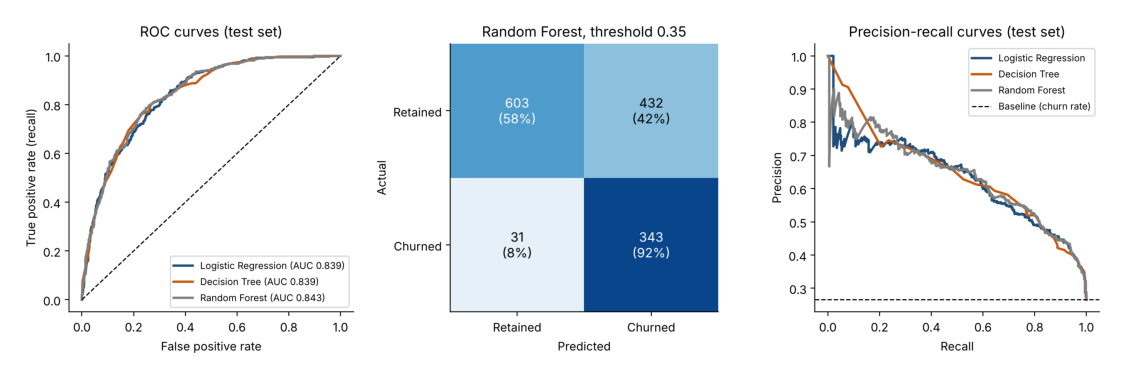

In [19]:
def show_image(path, width):
    image = plt.imread(path)
    plt.figure(figsize=(width, width * image.shape[0] / image.shape[1]))
    plt.imshow(image); plt.axis("off"); plt.show()

show_image("outputs/latest_run/model_evaluation.png", 13)

**Reading the figure.** *Left:* ROC curves for the three models almost overlap. *Middle:* confusion matrix for the best model at the recall-favoring threshold. *Right:* precision-recall curves; precision falls as recall rises, which is the trade-off the retention team must choose on.

In [20]:
# Unit and regression tests live in tests/ (run them with: python -m unittest discover -s tests -v)
import unittest

def flatten(suite):
    for item in suite:
        if isinstance(item, unittest.TestSuite):
            yield from flatten(item)
        else:
            yield item

all_tests = unittest.defaultTestLoader.discover("tests", pattern="test_churn_pipeline.py")
fast = unittest.TestSuite(t for t in flatten(all_tests) if "RegressionTest" not in t.id())   # skip the 30 s full rerun
outcome = unittest.TextTestRunner(verbosity=0, stream=sys.stdout).run(fast)
print(f"\nFast tests run: {outcome.testsRun} | failures: {len(outcome.failures)} | errors: {len(outcome.errors)}")

----------------------------------------------------------------------
Ran 12 tests in 0.261s

OK

Fast tests run: 12 | failures: 0 | errors: 0


---
## 8. Key Findings

### What drives churn?

In [21]:
top = pd.concat([
    odds.head(8).reset_index(drop=True)[["feature", "odds_ratio"]].round(2).add_prefix("logistic_"),
    importances.head(8).reset_index(drop=True).round(3).add_prefix("forest_"),
], axis=1)
top

,logistic_feature,logistic_odds_ratio,forest_feature,forest_importance
0,InternetService_No,0.20,Contract_Month-to-month,0.205
1,InternetService_Fiber optic,2.86,tenure,0.182
2,Contract_Two year,0.37,Contract_Two year,0.109
3,tenure,0.47,InternetService_Fiber optic,0.090
4,MonthlyCharges,0.57,MonthlyCharges,0.088
5,StreamingMovies_Yes,1.64,PaymentMethod_Electronic check,0.072
6,StreamingTV_Yes,1.60,InternetService_No,0.048
7,Contract_Month-to-month,1.55,Contract_One year,0.036


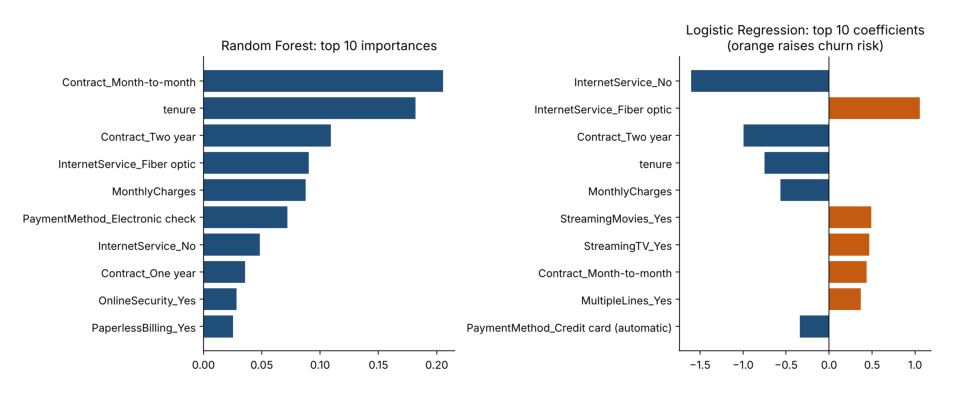

In [22]:
show_image("outputs/latest_run/feature_drivers.png", 11)

**Both models agree** with each other and with the exploratory analysis: contract type, tenure, and internet service type are the top drivers, followed by monthly charges and electronic-check payment. Odds ratios above 1 raise churn risk (for example, fiber optic about 2.9) and below 1 lower it (two-year contract about 0.37; no internet service about 0.20). They describe effects holding other features constant, so some coefficients differ from raw averages (for example, `MonthlyCharges` is negative because internet type and add-ons already carry much of the price information).

### Key findings
1. **Churn can be ranked well:** test ROC-AUC is about 0.84 for all three models.
2. **Churn is concentrated:** month-to-month customers are 55% of the base but 89% of churners; 55% of churners leave in the first 12 months; month-to-month fiber customers (30% of the base) account for 62% of all churners.
3. **Support and engagement matter:** customers with tech support or online security churn at about half the rate of those without; among internet customers churn falls from 52% with no add-ons to 5% with all six (an association, not proof of cause).
4. **The model's value depends on cost:** the best operating point depends on what a retention contact costs relative to the value of a saved customer (Section 9).

---
## 9. Business Value of the Model

The model ranks customers; whether to contact someone is an economic decision. A contact pays off when the share of flagged customers who really churn (precision) is above **c / (s × V)**, where *c* = cost per contact, *s* = share of contacted churners an offer retains, and *V* = value of a saved customer.

> **The inputs below are illustrative assumptions, not company data.** Change them in the next cell and re-run to see how the best strategy changes.

In [23]:
# ---- Editable assumptions (illustrative) ----
VALUE_MONTHS = 12            # months of revenue a saved customer is assumed to bring
SUCCESS_RATE = 0.30          # share of contacted churners that an offer retains
CONTACT_COSTS = [20, 100, 200]   # cost per contact in dollars (scenarios)

avg_monthly_charge = df.loc[df.churned == 1, "MonthlyCharges"].mean()
VALUE = VALUE_MONTHS * avg_monthly_charge
print(f"Value of a saved customer V = {VALUE_MONTHS} x ${avg_monthly_charge:.2f} = ${VALUE:,.0f} (revenue, not profit)")

# Rank test customers by predicted churn risk using the Logistic Regression model
X, y = data.load_data("data/processed/telco_clean.csv")
split = data.split_data(X, y)
logit = modeling.build_searches(X, modeling.make_cv())["Logistic Regression"].fit(split.X_train, split.y_train)
risk = logit.predict_proba(split.X_test)[:, 1]
churned_by_risk = split.y_test.values[np.argsort(-risk)]          # highest risk first
churners_reached = np.cumsum(churned_by_risk)
contacted = np.arange(1, len(churned_by_risk) + 1)
n_test, n_churners = len(churned_by_risk), churned_by_risk.sum()

gains = pd.DataFrame({"customers_contacted": [f"top {p}%" for p in (10, 20, 30, 40, 60)]})
idx = [int(round(n_test * p / 100)) - 1 for p in (10, 20, 30, 40, 60)]
gains["number"] = contacted[idx]
gains["churners_reached"] = churners_reached[idx]
gains["share_of_churners"] = (churners_reached[idx] / n_churners).round(3)
gains["lift_vs_random"] = (gains["share_of_churners"] / (contacted[idx] / n_test)).round(2)
gains

Value of a saved customer V = 12 x $74.44 = $893 (revenue, not profit)


,customers_contacted,number,churners_reached,share_of_churners,lift_vs_random
0,top 10%,141,106,0.283,2.83
1,top 20%,282,188,0.503,2.51
2,top 30%,423,239,0.639,2.13
3,top 40%,564,289,0.773,1.93
4,top 60%,845,351,0.939,1.57


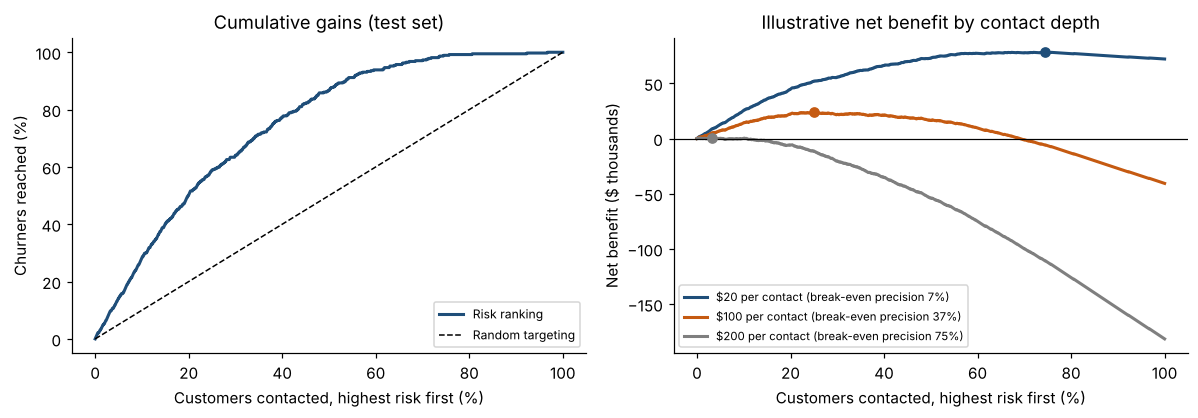

,cost_per_contact,best_depth,customers_contacted,best_net_benefit,contact_everyone
0,$20,top 75%,1050,"$78,156","$72,048"
1,$100,top 25%,354,"$23,826","-$40,672"
2,$200,top 3%,45,$648,"-$181,572"


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
ax[0].plot(np.r_[0, contacted / n_test * 100], np.r_[0, churners_reached / n_churners * 100], color=BLUE, lw=2, label="Risk ranking")
ax[0].plot([0, 100], [0, 100], "k--", lw=1, label="Random targeting")
ax[0].set(xlabel="Customers contacted, highest risk first (%)", ylabel="Churners reached (%)", title="Cumulative gains (test set)")
ax[0].legend(loc="lower right", fontsize=8)

def dollars(amount):
    return f"-${abs(amount):,.0f}" if amount < 0 else f"${amount:,.0f}"

best_rows = []
for cost, color in zip(CONTACT_COSTS, [BLUE, ORANGE, GRAY]):
    net = churners_reached * SUCCESS_RATE * VALUE - contacted * cost
    best = int(np.argmax(net))
    ax[1].plot(np.r_[0, contacted / n_test * 100], np.r_[0, net] / 1000, color=color, lw=2,
               label=f"${cost} per contact (break-even precision {cost / (SUCCESS_RATE * VALUE):.0%})")
    ax[1].scatter([(best + 1) / n_test * 100], [net[best] / 1000], color=color, zorder=5)
    best_rows.append({"cost_per_contact": f"${cost}", "best_depth": f"top {(best + 1) / n_test:.0%}",
                      "customers_contacted": best + 1, "best_net_benefit": dollars(net[best]),
                      "contact_everyone": dollars(net[-1])})
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(xlabel="Customers contacted, highest risk first (%)", ylabel="Net benefit ($ thousands)", title="Illustrative net benefit by contact depth")
ax[1].legend(fontsize=7.5, loc="lower left")
plt.tight_layout()
plt.show()

pd.DataFrame(best_rows)

**Lessons (under the default assumptions).** (1) Contacting the top 20% of customers reaches about half of all churners (2.5x better than random). (2) When contacts are cheap ($20), reaching about three-quarters of customers pays off. (3) When contacts cost $100, contacting everyone loses money and only the top 25% are worth contacting. (4) At $200, only the top 3% are worth contacting. **The model is most valuable when retention actions are expensive, and the contact depth must be set from the real cost per contact.**

---
## 10. Conclusions and Recommendations

### Conclusions
- **Objective 1 (drivers):** churn is most strongly associated with contract type, tenure, and internet service type, consistently across the exploratory analysis and both interpretable models.
- **Objective 2 (prediction):** the three models rank customers equally well (test AUC about 0.84). At the default threshold the models find about 78-80% of churners; at a recall-favoring threshold about 91-95%, at the cost of more false alarms.
- **Objective 3 (decisions):** a risk-ranked list reaches half of all churners by contacting 20% of customers; how deep to go depends on cost per contact versus the value of a saved customer.

### Recommendations

| # | Recommendation | Evidence | Priority |
|---|---|---|---|
| 1 | Score customers regularly; contact highest-risk first, with depth set by cost per contact | Top 20% reach 50% of churners | High |
| 2 | Build an onboarding and early-tenure program for months 1-12 | 47.4% churn in year one; 55% of churners leave in the first year | High |
| 3 | Test incentives to move month-to-month customers to longer contracts | 42.7% vs 11.3% / 2.8% churn; 89% of churners are month-to-month | High |
| 4 | Investigate the fiber-optic experience and price for month-to-month customers | 54.6% churn; 62% of all churners | High |
| 5 | Test automatic-payment and support/security add-on offers | Electronic check 45.3% vs 15-19%; no support/security about 31% vs 15% | Medium (could reflect engaged customers, so test) |
| 6 | Run a controlled retention experiment before scaling; retrain the model regularly | Business value depends on unmeasured success rate and cost | High |
| 7 | Target on behavior and contract, not demographics | No gender effect; age and partner effects are descriptive | Policy |

### Limitations
- **Proxy data:** a telecom dataset, not a streaming company's own data; streaming churn may depend on content and viewing behavior that are absent here.
- **Snapshot data:** no dates, so the model cannot say *when* a customer will leave; tenure is capped at 72 months.
- **Association, not causation:** interventions should be tested before they are assumed to work.
- **Illustrative economics:** the dollar figures in Section 9 are assumptions.
- **Single split of one dataset;** model differences are within noise.

### Future work
Add streaming-specific engagement data (viewing hours, logins, support tickets, price-change dates), build a time-to-churn (survival) model, calibrate probabilities, compare gradient boosting with repeated cross-validation, and replace the illustrative assumptions with real cost and retention data.

---
## 11. Repository Guide and Use of AI

### Project files

| Path | Contents |
|---|---|
| `README.md` | Project overview, results, how to run |
| `notebooks/Churn_Project_Presentation.ipynb` | This presentation notebook |
| `churn_pipeline/` | Documented Python package: `config`, `cleaning`, `data`, `modeling`, `evaluation`, `plotting`, `checks`, `pipeline` |
| `run_churn_model.py` | Command-line entry point |
| `tests/` | 13 automated tests (unit tests, cleaning test, regression test) |
| `data/raw/`, `data/processed/` | Raw IBM file, cleaned table, and model-ready table from the preparation milestone |
| `outputs/reference/` | Result tables and figures used in the final report (scikit-learn 1.8.0) |
| `figures/` | Figures used in the report |
| `reports/` | Proposal and all milestone reports, including the final technical report |
| `history/` | Original data prep script and earlier code versions (AI draft, pre-refactor) |

### Use of generative AI
I used Claude (Anthropic) during the project to help draft prompts, write and refactor the Python code, create tests, and organize documentation, including this notebook. AI-generated code was reviewed, run, and tested before use; the issues found in the first AI draft (overfitting, scaling leakage, redundant features) and the revisions made are documented in `reports/AI_Code_Milestone_Report.docx`, and the original draft is preserved in `history/`. I verified the reported numbers against program output and I take responsibility for the analysis, conclusions, and recommendations.

### References
- IBM. (n.d.). *Telco customer churn* [Data set]. GitHub. https://github.com/IBM/telco-customer-churn-on-icp4d
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Reichheld, F. F., & Sasser, W. E., Jr. (1990). Zero defections: Quality comes to services. *Harvard Business Review, 68*(5), 105-111.
- The full reference list is in `reports/Final_Technical_Report.docx`.